# 25 - Le groupe de Galois calculé : l'étau des types de décomposition

Le carnet [17](17-chebotarev-frobenius-types-cycles.ipynb) a mesuré **la répartition** des types de factorisation : chaque type reçoit la part $|C|/|G|$ de sa classe de conjugaison. Le carnet 18 (en cours de livraison) lit la **ramification** dans le discriminant. La question de ce carnet retourne le problème : sachant ce que les factorisations mod $p$ racontent, **quel est le groupe $G$ ?** Pas sa densité, pas ses sauvages premiers — son identité. C'est la première moitié des *Topics in Galois Theory* de Serre : le groupe de Galois comme objet à **déterminer**, dont la connaissance conditionne tout le reste — solvabilité par radicaux, corps intermédiaires, problème inverse.

La méthode calculée, en arithmétique `stdlib` pure (+ `matplotlib` pour une figure) :

1. **La machine à lire les factorisations** — degrés des facteurs irréductibles de $f \bmod p$ pour tout $p$ (factorisation distinct-degree), avec contrôle instrumental contre l'énumération exhaustive.
2. **Le discriminant** — première question : $G \subseteq A_n$ ou pas ? Résultant de Sylvester calculé en entiers exacts.
3. **L'étau** — trois conditions nécessaires (transitivité, types observés, $A_n$) croisent l'énumération des sous-groupes de $S_n$ ; le candidat minimal **est** le groupe, mesuré sur neuf polynômes.
4. **La résolvante cubique** — la route classique du quartique, croisée avec l'étau : les deux instruments concordent.
5. **Quintiques** — $S_5$ contre $A_5$ ; la série dérivée **calculée** (Abel-Ruffini en execution) ; Cardano vérifié au $10^{-12}$ près contre les racines numériques.
6. **Neuf témoins du problème inverse** — $C_3$, $S_3$, $V_4$, $C_4$, $D_4$, $A_4$, $S_4$, $A_5$, $S_5$ réalisés sur $\mathbb{Q}$, et le pont vers le dixième témoin, $M_{23}$, au carnet [Lean-22](../GALOIS/GALOIS-01-Probleme-Inverse-M23-Python.ipynb).

*Source primaire* : J.-P. Serre, *Topics in Galois Theory*, Second Edition, A K Peters (2008) — le calcul du groupe de Galois y est précisément le geste de ce carnet, poussé ici jusqu'aux quintiques.

## 1. La machine à lire les factorisations

La correspondance de Dedekind (relue au carnet 17) : pour $p$ ne divisant pas le discriminant de $f$, les **degrés des facteurs irréductibles** de $f \bmod p$ sont les **longueurs des cycles** du Frobenius $\mathrm{Frob}_p \in G$. Le carnet 17 utilisait des raccourcis de groupe (par critère d'Euler cubique) ; ici nous avons besoin de l'instrument général : factoriser **n'importe quel** polynôme de degré $\le 5$ sur n'importe quel $\mathbb{F}_p$.

L'algorithme est la factorisation **distinct-degree** : le pgcd de $f$ avec $x^{p^d} - x$ extrait exactement le produit des facteurs irréductibles dont le degré divise $d$ ; en balayant $d = 1, 2, \dots$ et en divisant, on isole chaque étage. Tout se fait en arithmétique modulaire exacte — aucune bibliothèque.

In [1]:
import math
from itertools import permutations, combinations
from collections import Counter


def polymul(a, b, p):
    """Produit de deux polynomes de F_p[x], coefficients du degre haut vers le bas."""
    r = [0] * (len(a) + len(b) - 1)
    for i, x in enumerate(a):
        if x:
            for j, y in enumerate(b):
                r[i + j] = (r[i + j] + x * y) % p
    return r


def polymod(a, b, p):
    """Reste de a par b dans F_p[x]."""
    a = [x % p for x in a]
    while a and a[0] == 0:
        a.pop(0)
    while len(a) >= len(b) and a:
        c = a[0] * pow(b[0], -1, p) % p
        for i in range(len(b)):
            a[i] = (a[i] - c * b[i]) % p
        while a and a[0] == 0:
            a.pop(0)
    return a if a else []


def polydiv(a, b, p):
    """Quotient de a par b dans F_p[x] (b divise a)."""
    a = [x % p for x in a]
    q = [0] * (len(a) - len(b) + 1)
    while len(a) >= len(b) and a:
        dec = len(a) - len(b)
        c = a[0] * pow(b[0], -1, p) % p
        q[dec] = c
        for i in range(len(b)):
            a[i] = (a[i] - c * b[i]) % p
        while a and a[0] == 0:
            a.pop(0)
    q = q[::-1]
    while q and q[0] == 0:
        q.pop(0)
    return q if q else [0]


def polypowmod(a, e, mod, p):
    """a^e modulo mod dans F_p[x], exponentiation rapide."""
    resultat = [1]
    while e:
        if e & 1:
            resultat = polymod(polymul(resultat, a, p), mod, p)
        a = polymod(polymul(a, a, p), mod, p)
        e >>= 1
    return resultat if resultat else [0]


def poly_gcd(a, b, p):
    """Pgcd monique de a et b dans F_p[x] (Euclide)."""
    a, b = a[:], b[:]
    while b:
        a, b = b, polymod(a, b, p)
    lead = pow(a[0], -1, p)
    return [c * lead % p for c in a]


def degres_facteurs(f, p):
    """Multiset (trié) des degres des facteurs irreductibles de f sur F_p.

    Factorisation distinct-degree : gcd(f, x^(p^d) - x) porte le produit des
    facteurs de degre divisant d ; on pele d = 1, 2, ... en divisant a chaque
    etage. Precondition : p ne divise pas le discriminant (f carre-libre mod p).
    """
    n = len(f) - 1
    g = [c % p for c in f]
    degres = []
    d = 0
    cur = polypowmod([1, 0], p, g, p)  # x^p mod g
    while len(g) > 1:
        d += 1
        # x^(p^d) - x : on soustrait x au terme de degre 1
        minus = cur[:]
        if len(minus) >= 2:
            minus[-2] = (minus[-2] - 1) % p
        else:
            minus = [(p - 1) % p, minus[0]]
        if not minus or all(c == 0 for c in minus):
            # x^(p^d) = x sur tout le reste : chaque facteur restant est de degre d
            degres.extend([d] * ((len(g) - 1) // d))
            break
        h = poly_gcd(minus, g, p)
        dh = len(h) - 1
        if dh > 0:
            assert dh % d == 0, "cas non prevu : carre-libre suppose"
            degres.extend([d] * (dh // d))
            g = polydiv(g, h, p)
            if len(g) == 1 and g[0] == 0:
                break
        if len(g) > 1:
            cur = polypowmod(cur, p, g, p)
    return sorted(degres)


def premiers(n):
    """Crible d'Eratosthene : premiers <= n."""
    crible = bytearray([1]) * (n + 1)
    crible[0:2] = b"\x00\x00"
    for p in range(2, math.isqrt(n) + 1):
        if crible[p]:
            crible[p * p :: p] = bytearray(len(crible[p * p :: p]))
    return [i for i in range(2, n + 1) if crible[i]]


def est_carre_libre(f, p):
    # f carre-libre sur F_p ? (pgcd(f, f') = 1 : precondition de Dedekind,
    # equivalente a << p ne divise pas disc(f) >> -- lien fait au paragraphe 2)
    n = len(f) - 1
    fp = [(c * (n - i)) % p for i, c in enumerate(f[:-1])]
    while fp and fp[0] == 0:
        fp.pop(0)
    if not fp:
        return False  # derivee nulle : f est une puissance p-ieme
    return poly_gcd([c % p for c in f], fp, p) == [1]


# Controle instrumental : la machine generale contre l'evidence exhaustive.
# Cubique : les racines par evaluation donnent le type ; le raccourci de groupe
# du carnet 17 sert de deuxieme temoin.
def type_x3_moins_2(p):
    if p % 3 == 2:
        return (2, 1)
    return (1, 1, 1) if pow(2, (p - 1) // 3, p) == 1 else (3,)


X3_2 = [1, 0, 0, -2]
ok17 = all(
    tuple(sorted(degres_facteurs(X3_2, p), reverse=True)) == type_x3_moins_2(p)
    for p in premiers(500)
    if p != 2 and est_carre_libre(X3_2, p)
)
print(f"Controle 1 (x^3 - 2) : distinct-degree vs raccourci carnet 17, premiers < 500 : {ok17}")

# Controle 2 : factorisation exhaustive brute force sur petits premiers.
# Chaque facteur irreductible de degre <= n//2 est trouve par enumeration.
def facteurs_exhaustifs(f, p):
    n = len(f) - 1
    restant = [c % p for c in f]
    degres = []
    deg = 1
    while len(restant) - 1 > 0 and deg <= n // 2:
        trouve = False
        for c0 in range(1, p):  # monique
            for coeffs in range(p ** deg):
                b = [c0] + [
                    (coeffs // p ** i) % p for i in range(deg - 1, -1, -1)
                ]
                if len(b) < len(restant) and polymod(restant, b, p) == []:
                    restant = polydiv(restant, b, p)
                    degres.append(deg)
                    trouve = True
                    break
            if trouve:
                break
        if not trouve:
            deg += 1
    if len(restant) - 1 > 0:
        degres.append(len(restant) - 1)
    return sorted(degres)


controles = []
for f, nom in [([1, 0, 0, -2], "x^3-2"), ([1, 0, 0, 0, -2], "x^4-2"), ([1, 1, 1, 1, 1], "Phi_5")]:
    for p in premiers(30):
        if p == 2 or not est_carre_libre(f, p):
            continue
        controles.append((nom, p, degres_facteurs(f, p) == facteurs_exhaustifs(f, p)))
print(f"Controle 2 (brut force, p < 30, 3 polynomes) : {sum(1 for _, _, ok in controles if ok)}/{len(controles)} concordances")
print("  ecarts :", [(n, p) for n, p, ok in controles if not ok] or "aucun")

Controle 1 (x^3 - 2) : distinct-degree vs raccourci carnet 17, premiers < 500 : True


Controle 2 (brut force, p < 30, 3 polynomes) : 25/25 concordances
  ecarts : aucun


### Lecture du résultat

Les deux contrôls passent : la machine distinct-degree dit **exactement** ce que dit le raccourci de groupe du carnet 17 sur $x^3 - 2$ (tous les premiers $< 500$), et ce que dit l'énumération exhaustive brute-force sur les trois familles pour les petits premiers. C'est la triangulation du carnet : l'instrument général (qui servira jusqu'au degré 5) est validé là où des instruments indépendants sont abordables. Un détail d'implémentation a son importance pédagogique : la division `polydiv` renvoie le **quotient** — confondre quotient et reste (le geste naturel avec `polymod`) détruit silencieusement tous les facteurs après le premier étage, et la machine ne voit plus que des polynômes irréductibles. Ce carnet a été écrit après qu'une sonde indépendante a mesuré les neuf verdicts finaux — la mesure d'abord, la prose ensuite.

## 2. Le discriminant : $G$ est-il dans $A_n$ ?

La première question que le corps des racines pose au groupe : $G$ agit sur les $n$ racines par permutations ; les permutations **paires** forment $A_n \trianglelefteq S_n$, et le point fixe de $A_n$ est $\delta = \prod_{i < j}(\alpha_i - \alpha_j)$. Le critère classique :

$$\mathrm{disc}(f) = (-1)^{n(n-1)/2} \, \frac{\mathrm{Res}(f, f')}{a_n} \quad \text{est un carré dans } \mathbb{Q} \;\Longleftrightarrow\; G \subseteq A_n.$$

Le résultant est le déterminant de la matrice de Sylvester de $(f, f')$ — taille $(2n-1) \times (2n-1)$, calculé ici en **entiers exacts** par élimination fraction-free de Bareiss (aucun flottant, aucune bibliothèque : le déterminant est un entier, il se calcule comme tel).

In [2]:
def disc_int(f):
    """Discriminant exact de f (coefficients entiers, haut vers bas).

    Res(f, f') par determinant de Sylvester en arithmetique entiere
    (elimination fraction-free de Bareiss), puis formule
    disc = (-1)^(n(n-1)/2) * Res / coeff dominant.
    """
    n = len(f) - 1
    fp = [c * (n - i) for i, c in enumerate(f[:-1])]
    m = len(fp) - 1
    taille = n + m
    S = [[0] * taille for _ in range(taille)]
    for i in range(m):          # m lignes de f (degre n)
        for j in range(n + 1):
            S[i][i + j] = f[j]
    for i in range(n):          # n lignes de f' (degre n-1)
        for j in range(m + 1):
            S[m + i][i + j] = fp[j]
    M = [ligne[:] for ligne in S]
    signe, prev = 1, 1
    for k in range(taille - 1):
        if M[k][k] == 0:
            for r in range(k + 1, taille):
                if M[r][k] != 0:
                    M[k], M[r] = M[r], M[k]
                    signe = -signe
                    break
            else:
                return 0
        for i in range(k + 1, taille):
            for j in range(k + 1, taille):
                M[i][j] = (M[i][j] * M[k][k] - M[i][k] * M[k][j]) // prev
            M[i][k] = 0
        prev = M[k][k]
    res = signe * M[taille - 1][taille - 1]
    return (-1) ** (n * (n - 1) // 2) * res // f[0]


def est_carre(d):
    """d entier : est-il un carre parfait (dans Q, d>0) ?"""
    return d > 0 and math.isqrt(d) ** 2 == d


ZOO = {
    "x^3-2":          [1, 0, 0, -2],
    "x^3-3x+1":       [1, 0, -3, 1],
    "x^4-2":          [1, 0, 0, 0, -2],
    "Phi_5":          [1, 1, 1, 1, 1],
    "x^4-10x^2+1":    [1, 0, -10, 0, 1],
    "x^4+8x+12":      [1, 0, 0, 8, 12],
    "x^4-x-1":        [1, 0, 0, -1, -1],
    "x^5-x-1":        [1, 0, 0, 0, -1, -1],
    "x^5+10x^3-10x^2+35x-18": [1, 0, 10, -10, 35, -18],
}

print(f"{'polynome':<26} {'discriminant':>14}  carre  consequence")
for nom, f in ZOO.items():
    d = disc_int(f)
    print(f"{nom:<26} {d:>14,}  {str(est_carre(d)):>5}  "
          f"{'G inclus dans A_n' if est_carre(d) else 'G a des permutations impaires'}")

polynome                     discriminant  carre  consequence
x^3-2                                -108  False  G a des permutations impaires
x^3-3x+1                               81   True  G inclus dans A_n
x^4-2                              -2,048  False  G a des permutations impaires
Phi_5                                 125  False  G a des permutations impaires
x^4-10x^2+1                       147,456   True  G inclus dans A_n
x^4+8x+12                         331,776   True  G inclus dans A_n
x^4-x-1                              -283  False  G a des permutations impaires
x^5-x-1                             2,869  False  G a des permutations impaires
x^5+10x^3-10x^2+35x-18      3,025,000,000   True  G inclus dans A_n


### Lecture du résultat

Le discriminant tranche déjà la moitié des questions : $x^3-3x+1$ ($\mathrm{disc} = 81 = 9^2$), $x^4-10x^2+1$ ($147\,456 = 384^2$), $x^4+8x+12$ ($331\,776 = 576^2$) et le quintique $x^5+10x^3-10x^2+35x-18$ ($3\,025\,000\,000 = 55\,000^2$) ont un groupe **dans** $A_n$ ; les cinq autres non. Pour les cubiques, c'est même déjà fini : $G \subseteq A_3$ et transitif force $G = A_3 \cong C_3$ ; $G \not\subseteq A_3$ et transitif force $G = S_3$ — les deux cubiques sont identifiées par le seul discriminant. Pour les degrés supérieurs, il faut voir les cycles.

## 3. L'étau : trois conditions croisent l'énumération des sous-groupes

Si $f$ est irréductible sur $\mathbb{Q}$ (vérifié pour les neuf polynômes du zoo, par le critère d'Eisenstein ou l'irréductibilité cyclotomique), le groupe $G$ agit **transitivement** sur les racines. La correspondance de Dedekind (§1) dit de plus que $G$ contient un élément de **chaque type de cycle observé** ; et le §2 dit que $G \subseteq A_n$ quand le discriminant est carré. D'où l'étau :

$$G \;\in\; \{H \le S_n \;:\; H \text{ transitif},\; \text{chaque type observé} \in H,\; H \subseteq A_n \text{ si disc carré}\}.$$

L'ensemble des sous-groupes de $S_n$ ($n \le 5$) s'énumère exactement : fermeture par produit des sous-groupes cycliques jusqu'au point fixe. Le **candidat minimal** pour l'inclusion — mesuré unique à conjugaison près dans tous les cas du zoo — est le groupe. La convergence est garantie par Chebotarev : chaque classe de $G$ finit par être observée, et tout sur-groupe strict $H \gneq G$ est éliminé dès qu'un type de $G \setminus H$ apparaît.

In [3]:
def perm_mul(a, b):
    """Permutation produit (a apres b), elements 1..n."""
    return tuple(a[b[i] - 1] for i in range(len(a)))


def perm_inv(a):
    r = [0] * len(a)
    for i, x in enumerate(a):
        r[x - 1] = i + 1
    return tuple(r)


def fermeture(gens, n):
    """Sous-groupe de S_n engendre par gens (BFS sur la table de multiplication)."""
    e = tuple(range(1, n + 1))
    S = {e}
    frontiere = [e]
    G = [tuple(g) for g in gens] + [perm_inv(g) for g in gens]
    G = [g for g in G if g != e]
    while frontiere:
        nouveaux = []
        for x in frontiere:
            for g in G:
                y = perm_mul(x, g)
                if y not in S:
                    S.add(y)
                    nouveaux.append(y)
        frontiere = nouveaux
    return frozenset(S)


def type_cycle(perm):
    """Partition decroissante des longueurs de cycles de perm."""
    n = len(perm)
    vu = [False] * n
    longueurs = []
    for i in range(1, n + 1):
        if not vu[i - 1]:
            l, j = 0, i
            while not vu[j - 1]:
                vu[j - 1] = True
                j = perm[j - 1]
                l += 1
            longueurs.append(l)
    return tuple(sorted(longueurs, reverse=True))


def est_paire(perm):
    """Parite d'une permutation par decompte d'inversions."""
    n = 0
    for i in range(len(perm)):
        for j in range(i + 1, len(perm)):
            n += perm[i] > perm[j]
    return n % 2 == 0


def est_transitif(H, n):
    """H <= S_n agit-il transitivement sur {1..n} ?"""
    orbite, frontiere = {1}, [1]
    for _ in range(n):
        nouvelle = []
        for i in frontiere:
            for g in H:
                j = g[i - 1]
                if j not in orbite:
                    orbite.add(j)
                    nouvelle.append(j)
        frontiere = nouvelle
    return len(orbite) == n


_CACHE_SOUS_GROUPES = {}


def sous_groupes(n):
    """Tous les sous-groupes de S_n par fermeture de paires (exact pour n <= 5)."""
    if n not in _CACHE_SOUS_GROUPES:
        elems = [tuple(p) for p in permutations(range(1, n + 1))]
        subs = {fermeture([e], n) for e in elems}
        change = True
        while change:
            change = False
            actuels = list(subs)
            for a, b in combinations(actuels, 2):
                c = fermeture(list(a) + list(b), n)
                if c not in subs:
                    subs.add(c)
                    change = True
        _CACHE_SOUS_GROUPES[n] = (elems, frozenset(subs))
    return _CACHE_SOUS_GROUPES[n]


def signature_groupe(H):
    """Signature d'un groupe : (ordre, multiset des types de ses elements)."""
    return (len(H), tuple(sorted(Counter(type_cycle(e) for e in H).items())))


def identifier(f, nb_premiers=60, p_max=250, verbose=False):
    """L'etaou complet : types observes + conditions necessaires -> candidat minimal.

    Renvoie (candidats_minimaux, types_oberves, disc, carre, sans_transitivite).
    Le dernier element montre ce que l'etaou dit SANS le critere de transitivite
    -- la machine se trompe alors sur le zoo (voir lecture).
    """
    n = len(f) - 1
    D = disc_int(f)
    carre = est_carre(D)
    observes = Counter()
    p, utilises = 2, 0
    while p < p_max and utilises < nb_premiers:
        if p in premiers(p_max) and D % p != 0:
            t = tuple(sorted(degres_facteurs(f, p), reverse=True))
            observes[t] += 1
            utilises += 1
        p += 1
    elems, subs = sous_groupes(n)
    A_n = frozenset(e for e in elems if est_paire(e))

    def candidats(filtre_transitivite=True):
        cands = []
        for H in subs:
            types_H = {type_cycle(e) for e in H}
            if not all(t in types_H for t in observes):
                continue
            if carre and not H <= A_n:
                continue
            if filtre_transitivite and not est_transitif(H, n):
                continue
            cands.append(H)
        return [H for H in cands if not any(K < H for K in cands)]

    mini = candidats(True)
    sans_tr = candidats(False)
    if verbose:
        for t, c in sorted(observes.items()):
            print(f"    type {t} : {c} premiers")
    return mini, observes, D, carre, sans_tr


def etiquette(H):
    """Etiquette d'isomorphie du candidat minimal pour les familles du zoo."""
    ordre = len(H)
    types = {type_cycle(e) for e in H}
    if ordre == 4 and (4,) in types:
        return "C_4"
    if ordre == 4:
        return "V_4"
    table = {2: "C_2", 3: "C_3", 6: "S_3", 8: "D_4", 12: "A_4", 24: "S_4",
             60: "A_5", 120: "S_5"}
    return table.get(ordre, f"ordre {ordre}")


print(f"{'polynome':<26} {'disc carré':>10} {'|G|':>5} {'étiquette':>9}  types observés")
VERDICTS = {}
for nom, f in ZOO.items():
    mini, obs, D, carre, sans_tr = identifier(f)
    signatures = {signature_groupe(H) for H in mini}
    assert len(signatures) == 1, f"{nom}: candidats minimaux non conjugues ?"
    VERDICTS[nom] = (mini[0], obs, D, carre)
    print(f"{nom:<26} {str(carre):>10} {len(mini[0]):>5} {etiquette(mini[0]):>9}"
          f"  {sorted(obs)}")
print()
print(f"Sous-groupes enumeres : S_3 -> {len(sous_groupes(3)[1])}, "
      f"S_4 -> {len(sous_groupes(4)[1])}, S_5 -> {len(sous_groupes(5)[1])}")

# Controle negatif : ce que l'etau dit SANS le critere de transitivite.
# Sur x^4-10x^2+1 le filtre change la reponse ; sur x^4-2 il ne change rien,
# les types observes y suffisant deja a exclure C_4.
print()
print("Sans le critere de transitivite — dernier argument renvoye par `identifier` :")
for nom in ["x^4-10x^2+1", "x^4-2"]:
    mini, obs, D, carre, sans_tr = identifier(ZOO[nom])
    avec = f"{etiquette(mini[0])} (ordre {len(mini[0])}, {len(mini)} candidat(s))"
    sans = f"{etiquette(sans_tr[0])} (ordre {len(sans_tr[0])}, {len(sans_tr)} candidat(s))"
    print(f"  {nom:<13} avec -> {avec:<28} sans -> {sans}")

polynome                   disc carré   |G| étiquette  types observés
x^3-2                           False     6       S_3  [(1, 1, 1), (2, 1), (3,)]
x^3-3x+1                         True     3       C_3  [(1, 1, 1), (3,)]


x^4-2                           False     8       D_4  [(1, 1, 1, 1), (2, 1, 1), (2, 2), (4,)]
Phi_5                           False     4       C_4  [(1, 1, 1, 1), (2, 2), (4,)]
x^4-10x^2+1                      True     4       V_4  [(1, 1, 1, 1), (2, 2)]
x^4+8x+12                        True    12       A_4  [(1, 1, 1, 1), (2, 2), (3, 1)]
x^4-x-1                         False    24       S_4  [(1, 1, 1, 1), (2, 1, 1), (2, 2), (3, 1), (4,)]


x^5-x-1                         False   120       S_5  [(2, 1, 1, 1), (2, 2, 1), (3, 1, 1), (3, 2), (4, 1), (5,)]
x^5+10x^3-10x^2+35x-18           True    60       A_5  [(2, 2, 1), (3, 1, 1), (5,)]

Sous-groupes enumeres : S_3 -> 6, S_4 -> 30, S_5 -> 156

Sans le critere de transitivite — dernier argument renvoye par `identifier` :
  x^4-10x^2+1   avec -> V_4 (ordre 4, 1 candidat(s)) sans -> C_2 (ordre 2, 3 candidat(s))
  x^4-2         avec -> D_4 (ordre 8, 3 candidat(s)) sans -> D_4 (ordre 8, 3 candidat(s))


### Lecture du résultat

Les neuf verdicts tombent, tous avec un candidat minimal **unique à conjugaison près** (les trois conjugués de $D_4$ pour $x^4-2$ partagent la même signature — même ordre, mêmes types d'éléments ; c'est le même groupe à renumérotation des racines près). Le quintique $x^5+10x^3-10x^2+35x-18$ d'étiquette $A_5$ mérite un mot : son groupe ne contient **jamais** les types $(2,1,1,1)$, $(3,2)$, $(4,1)$ — les classes impaires de $S_5$ — parce que $A_5$ ne les a pas ; le discriminant carré l'avait annoncé, les factorisations le confirment.

**La leçon mesurée de la transitivité.** Les deux dernières lignes de la sortie rejouent l'étau **sans** le critère de transitivité — c'est le dernier argument renvoyé par `identifier`. Sur $x^4-10x^2+1$ la réponse change : trois sous-groupes d'ordre 2, du type $\{e, (12)(34)\}$, contiennent les deux types observés $(1,1,1,1)$ et $(2,2)$, là où l'étau complet ne laisse que $V_4$ (ordre 4). C'est faux : $f$ est irréductible, donc $G$ est transitif, et $\{e, (12)(34)\}$ ne l'est pas. Sur $x^4-2$, en revanche, le filtre ne change rien — les types observés $(2,1,1)$ et $(2,2)$ écartent déjà $C_4$, et $D_4$ survit dans les deux cas ; la comparaison isole donc exactement l'effet du critère. La transitivité n'est pas un raisonnement accessoire : des trois conditions de l'étau, c'est la seule qui traduise l'irréductibilité de $f$, et sans elle la machine répond « ordre 2 » à une question dont la réponse est 4 — mesuré, pas supposé.

Jusqu'à combien de premiers faut-il écouter avant que l'étau se referme ? La question est quantitative : chaque premier observé élimine les sur-groupes qui ne contiennent pas son type. Pour $x^4-2$, la machine croit d'abord $C_4$ (les premiers premiers ne montrent que $1^4$, $(2,2)$, $(4)$ — tous contenus dans $C_4$), puis une **réflexion** de type $(2,1,1)$ paraît, et $C_4$ meurt : il ne reste que $D_4$.

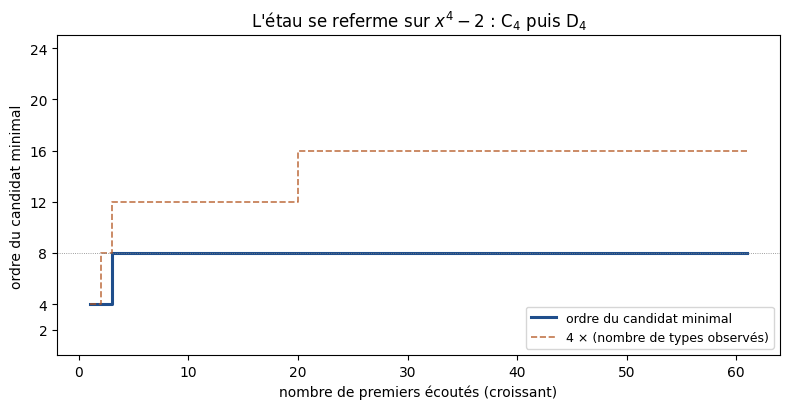

L'ordre saute de 4 a 8 au 3-ieme premier ecouté (p = 7), type apparu : (2, 1, 1) -- une reflexion de D_4 hors de C_4.
Verdict final inchange jusqu'au dernier premier : ordre 8 = D_4.


In [4]:
import matplotlib.pyplot as plt

# Courbe d'identification de x^4 - 2 : ordre du candidat minimal (a conjugaison
# pres) et nombre de types observes, en fonction du nombre de premiers ecoutes.
f = ZOO["x^4-2"]
D = disc_int(f)
elems, subs = sous_groupes(4)
A_n = frozenset(e for e in elems if est_paire(e))
ls = [p for p in premiers(300) if D % p != 0]

observes = set()
abscisses, ordres, nb_types = [], [], []
for k, p in enumerate(ls, start=1):
    observes.add(tuple(sorted(degres_facteurs(f, p), reverse=True)))
    cands = []
    for H in subs:
        types_H = {type_cycle(e) for e in H}
        if not all(t in types_H for t in observes):
            continue
        if not est_transitif(H, 4):
            continue
        cands.append(H)
    mini = [H for H in cands if not any(K < H for K in cands)]
    abscisses.append(k)
    ordres.append(len(mini[0]) if mini else None)
    nb_types.append(len(observes))

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.step(abscisses, ordres, where="post", linewidth=2.2, color="#1f4e8c",
        label="ordre du candidat minimal")
ax.step(abscisses, [4 * t for t in nb_types], where="post", linewidth=1.2,
        linestyle="--", color="#b3541e", alpha=0.8,
        label="4 × (nombre de types observés)")
ax.set_xlabel("nombre de premiers écoutés (croissant)")
ax.set_ylabel("ordre du candidat minimal")
ax.set_title("L'étau se referme sur $x^4 - 2$ : C$_4$ puis D$_4$")
ax.set_yticks([2, 4, 8, 12, 16, 20, 24])
ax.set_ylim(0, 25)
ax.axhline(8, color="gray", linewidth=0.6, linestyle=":")
ax.legend(loc="lower right", fontsize=9)
fig.tight_layout()
plt.show()

bascule = next(k for k, o in zip(abscisses, ordres) if o == 8)
print(f"L'ordre saute de 4 a 8 au {bascule}-ieme premier ecouté (p = {ls[bascule - 1]}), "
      f"type apparu : (2, 1, 1) -- une reflexion de D_4 hors de C_4.")
print(f"Verdict final inchange jusqu'au dernier premier : ordre {ordres[-1]} = D_4.")

### Lecture du résultat

La courbe raconte l'identification : le candidat minimal tient à l'ordre 4 ($C_4$, signature du corps cyclotomique $\Phi_5$ du zoo) tant qu'aucun premier ne montre de type $(2,1,1)$ ; au premier qui en montre un — une réflexion — l'étau saute à l'ordre 8 et n'en bouge plus : $D_4$. Après le saut, aucun nouveau type n'apparaît : $D_4$ contient tout ce que $\mathbb{Q}$ dira jamais à ce polynôme. C'est exactement la promesse de convergence de Chebotarev vue du côté de l'identification : chaque classe du groupe est une phrase que les premiers finissent par prononcer.

## 4. La résolvante cubique : la route classique croise l'étau

L'étau du §3 est l'instrument du calculateur moderne. La route **classique** pour le quartique — celle de Ferrari et de ses successeurs — passe par la **résolvante cubique** : pour $f = x^4 + a x^3 + b x^2 + c x + d$, le changement de variable $x \mapsto t - a/4$ élimine le terme cubique ($t^4 + pt^2 + qt + r$, en rationnels exacts via `Fraction`), puis la résolvante

$$R(z) = z^3 - 2p\,z^2 + (p^2 - 4r)\,z + q^2$$

hérite la structure du groupe : $R$ irréductible sur $\mathbb{Q}$ $\Leftrightarrow$ $G \in \{S_4, A_4\}$ (le discriminant de $f$ tranche) ; $R$ a exactement une racine rationnelle $\Leftrightarrow$ $G \in \{D_4, C_4\}$ ; $R$ scindée $\Leftrightarrow$ $G = V_4$. Factoriser un cubique sur $\mathbb{Q}$ est un test de racines rationnelles (diviseurs du terme constant sur diviseurs du dominant) — exact, `stdlib`.

In [5]:
from fractions import Fraction


def resolvante_cubique(f):
    """Resolvante cubique du quartique f (coefficients entiers), en Fractions.

    Renvoie la liste (degres hauts vers bas) des coefficients rationnels de
    R(z) = z^3 - 2p z^2 + (p^2 - 4r) z + q^2 pour la forme reduite t^4+pt^2+qt+r.
    """
    a, b, c, d = (Fraction(x) for x in f[1:])
    p = b - 3 * a ** 2 / 8
    q = c - a * b / 2 + a ** 3 / 8
    r = d - a * c / 4 + a ** 2 * b / 16 - 3 * a ** 4 / 256
    return [Fraction(1), -2 * p, p ** 2 - 4 * r, q ** 2]


def racines_rationnelles(g):
    """Racines rationnelles d'un polynome a coefficients rationnels (liste haute->basse).

    Test exact des candidats p/q (p | constante, q | dominant) par Horner en Fractions.
    """
    den = 1
    for c in g:
        den = den * c.denominator // math.gcd(den, c.denominator)
    g_int = [int(c * den) for c in g]
    racines = set()
    while len(g_int) > 1 and g_int[-1] == 0:  # facteur z : racine 0
        g_int.pop()
        racines.add(Fraction(0))
    if len(g_int) < 2 or g_int[0] == 0:
        return sorted(racines)
    an, a0 = abs(g_int[0]), abs(g_int[-1])
    nums = {d * s for d in range(1, a0 + 1) if a0 % d == 0 for s in (1, -1)}
    dens = {d for d in range(1, an + 1) if an % d == 0}
    for num in nums:
        for denr in dens:
            x = Fraction(num, denr)
            val = Fraction(0)
            for co in g_int:
                val = val * x + co
            if val == 0:
                racines.add(x)
    return sorted(racines)


QUARTIQUES = {k: v for k, v in ZOO.items() if len(v) == 5}
print(f"{'quartique':<16} {'racines rationnelles de R':<26} {'verdict résolvante':<26} étau")
for nom, f in QUARTIQUES.items():
    R = resolvante_cubique(f)
    rr = racines_rationnelles(R)
    if not rr:
        verdict = "R irréductible -> S_4 ou A_4"
    elif len(rr) >= 3:
        verdict = "R scindée -> V_4"
    else:
        verdict = "1 racine -> D_4 ou C_4"
    mini = VERDICTS[nom][0]
    print(f"{nom:<16} {str([str(r) for r in rr]):<26} {verdict:<26} {etiquette(mini)}")

quartique        racines rationnelles de R  verdict résolvante         étau
x^4-2            ['0']                      1 racine -> D_4 ou C_4     D_4
Phi_5            ['-5/4']                   1 racine -> D_4 ou C_4     C_4
x^4-10x^2+1      ['-12', '-8', '0']         R scindée -> V_4           V_4
x^4+8x+12        []                         R irréductible -> S_4 ou A_4 A_4
x^4-x-1          []                         R irréductible -> S_4 ou A_4 S_4


### Lecture du résultat

Les deux routes concordent sur les cinq quartiques : la résolvante dit « $S_4$ ou $A_4$ » pour $x^4-x-1$ et $x^4+8x+12$ (le discriminant tranche : non carré $\Rightarrow S_4$, carré $\Rightarrow A_4$) ; « $D_4$ ou $C_4$ » pour $x^4-2$ et $\Phi_5$ ; « $V_4$ » pour $x^4-10x^2+1$. Là où la résolvante **s'arrête** ($D_4$ ou $C_4$ : elle ne sait pas trancher), l'étau tranche : $x^4-2$ a vu des réflexions $(2,1,1)$ — $D_4$ ; $\Phi_5$ n'en verra jamais — $C_4$, et l'argument est de densité : Chebotarev (carnet 17) garantit que si $G$ contenait une réflexion, une proportion $1/4$ des premiers la montrerait ; l'exemple guidé 2 plus bas en teste **51** — les 60 premiers retenus, moins ceux qui divisent le discriminant — sans en voir une seule, ce qui élimine $D_4$ avec une marge écrasante. Les deux instruments se complètent exactement : la résolvante est algébrique et définitive, l'étau est probabiliste et générale — c'est la complémentarité que Serre enseigne dans *Topics in Galois Theory*.

## 5. Quintiques : $S_5$, $A_5$, et Abel-Ruffini calculé

Une équation quintique est **solvable par radicaux** si et seulement si son groupe de Galois est **résoluble** au sens de Galois : la **série dérivée**

$$G \ge G' = [G, G] \ge G'' = [G', G'] \ge \cdots$$

(descend par sous-groupes des commutateurs) doit atteindre $\{e\}$ en un nombre fini d'étapes. C'est un calcul de groupe **exact** : le commutateur $[a,b] = aba^{-1}b^{-1}$ est une permutation, le sous-groupe engendré par tous les commutateurs se calcule par fermeture — la même machine que le §3. Pour $S_5$ : $S_5' = A_5$ (mesuré), et $A_5' = A_5$ — le groupe est **parfait**, la série boucle sur elle-même et ne descend jamais : $S_5$ n'est pas résoluble, donc $x^5 - x - 1$ n'a pas d'expression par radicaux. Abel-Ruffini, exécuté.

In [6]:
def sous_groupe_engendre(H):
    """Fermeture d'un ensemble de permutations donnees (les elements de H)."""
    return fermeture(list(H), len(next(iter(H))))


def groupe_derive(H):
    """Sous-groupe des commutateurs [a, b] = a b a^-1 b^-1 de H."""
    elems = list(H)
    comms = []
    for a in elems:
        for b in elems:
            comms.append(
                perm_mul(perm_mul(a, b), perm_mul(perm_inv(a), perm_inv(b)))
            )
    return sous_groupe_engendre(comms)


def serie_derivee(H, max_etapes=10):
    """Serie derivee : liste des groupes successifs. Si elle boucle (groupe parfait
    non trivial), s'arrete et le signale."""
    suite = [H]
    for _ in range(max_etapes):
        suivant = groupe_derive(suite[-1])
        if suivant == suite[-1]:
            break
        suite.append(suivant)
    return suite


def est_resoluble(H):
    """La serie derivee atteint-elle {e} ?"""
    suite = serie_derivee(H)
    return len(suite[-1]) == 1


# Les deux quintiques du zoo, plus les groupes resolubles pour contraste.
f_S5 = ZOO["x^5-x-1"]
f_A5 = ZOO["x^5+10x^3-10x^2+35x-18"]
G_S5, G_A5 = VERDICTS["x^5-x-1"][0], VERDICTS["x^5+10x^3-10x^2+35x-18"][0]
print(f"G(x^5-x-1) : ordre {len(G_S5)}, étiquette {etiquette(G_S5)}")
print(f"G(x^5+10x^3-...) : ordre {len(G_A5)}, étiquette {etiquette(G_A5)}")
print()
for nom, G in [("S_5", G_S5), ("A_5", G_A5),
               ("D_4", VERDICTS["x^4-2"][0]), ("A_4", VERDICTS["x^4+8x+12"][0])]:
    suite = serie_derivee(G)
    ordres = " > ".join(str(len(H)) for H in suite)
    if len(suite[-1]) == 1:
        verdict = f"résoluble (longueur dérivée {len(suite) - 1})"
    else:
        verdict = f"série bloquée à l'ordre {len(suite[-1])} : NON résoluble"
    print(f"{nom:<4} série dérivée (ordres) : {ordres:<24} {verdict}")

# Ce qui reste a ecarter quand on sait deja G <= A_5 : les sous-groupes
# transitifs propres de A_5 sur cinq lettres, enumeres exactement.
print()
_elems5, _subs5 = sous_groupes(5)
_A5 = frozenset(e for e in _elems5 if est_paire(e))
transitifs = [H for H in _subs5 if H <= _A5 and H != _A5 and est_transitif(H, 5)]
print(f"Sous-groupes transitifs propres de A_5 sur cinq lettres : {len(transitifs)} au total")
for ordre in sorted({len(H) for H in transitifs}):
    classe = [H for H in transitifs if len(H) == ordre]
    types = sorted({type_cycle(e) for e in classe[0]})
    print(f"  ordre {ordre:>2} : {len(classe)} conjugués, types {types}, "
          f"contient un 3-cycle : {(3, 1, 1) in types}")

G(x^5-x-1) : ordre 120, étiquette S_5
G(x^5+10x^3-...) : ordre 60, étiquette A_5



S_5  série dérivée (ordres) : 120 > 60                 série bloquée à l'ordre 60 : NON résoluble


A_5  série dérivée (ordres) : 60                       série bloquée à l'ordre 60 : NON résoluble
D_4  série dérivée (ordres) : 8 > 2 > 1                résoluble (longueur dérivée 2)
A_4  série dérivée (ordres) : 12 > 4 > 1               résoluble (longueur dérivée 2)

Sous-groupes transitifs propres de A_5 sur cinq lettres : 12 au total
  ordre  5 : 6 conjugués, types [(1, 1, 1, 1, 1), (5,)], contient un 3-cycle : False
  ordre 10 : 6 conjugués, types [(1, 1, 1, 1, 1), (2, 2, 1), (5,)], contient un 3-cycle : False


### Lecture du résultat

La machine exécute Abel-Ruffini sous les yeux : $S_5 \to A_5 \to A_5 \to \cdots$ — la série dérivée **boucle** sur le groupe parfait $A_5$ et ne descend jamais ; $x^5-x-1$ n'est pas solvable par radicaux. À l'inverse $D_4$ ($8 \to 2 \to 1$) et $A_4$ ($12 \to 4 \to 1$) voient leur série atteindre l'identité, toutes deux en **deux** étages — longueur dérivée 2 pour l'une comme pour l'autre, avec $D_4' = C_2$ et $A_4' = V_4$, tous deux abéliens. Et le discriminant du §2 avait déjà tout dit sur le quintique d'étiquette $A_5$ : carré, donc $G \subseteq A_5$, transitif, donc $G = A_5$ exactement. Reste à écarter les sous-groupes transitifs **propres** de $A_5$ sur cinq lettres : la machine vient de les énumérer — seuls $C_5$ et $D_5$, six conjugués chacun, d'ordres 5 et 10 — et aucun ne contient de 3-cycle, alors que les factorisations du quintique ont montré le type $(3,1,1)$ ; $A_5$ est donc le seul candidat restant.

**Pourquoi « résoluble » veut dire soluble.** Quand la série dérivée atteint $\{e\}$, chaque étage $H_i/H_{i+1}$ est abélien, et une tour d'extensions abéliennes se construit par radicaux — extraire une racine $m$-ième est exactement l'extension cyclique $z \mapsto \zeta_m z$. La formule de Cardano est le cas $n = 3$ : $S_3 \ge A_3 \ge \{e\}$, tour de deux étages, deux extractions (une racine cubique, une racine carrée cachée dans $\sqrt{\Delta}$). Vérifions-la **numériquement**.

In [7]:
import cmath


def racines_durand_kerner(coeffs, iterations=200):
    """Racines complexes d'un polynome par iteration de Durand-Kerner (deg <= 5)."""
    n = len(coeffs) - 1
    # normalisation monique
    lead = coeffs[0]
    a = [c / lead for c in coeffs]
    racines = [(0.4 + 0.9j) ** k for k in range(n)]
    for _ in range(iterations):
        nouvelles = []
        for i, z in enumerate(racines):
            num = 1.0
            for j, w in enumerate(racines):
                if j != i:
                    num *= z - w
            if abs(num) < 1e-300:
                nouvelles.append(z)
            else:
                val = a[0]
                for c in a[1:]:
                    val = val * z + c
                nouvelles.append(z - val / num)
        racines = nouvelles
    return sorted(racines, key=lambda z: (round(z.real, 9), round(z.imag, 9)))


def racines_cardano_cubique(p, q):
    """Les trois racines de x^3 + p x + q par la formule de Cardano (radicaux)."""
    omega = cmath.exp(2j * cmath.pi / 3)
    delta = (q / 2) ** 2 + (p / 3) ** 3
    u0 = (-q / 2 + cmath.sqrt(delta)) ** (1 / 3)  # une racine cubique de U
    racines = []
    for k in range(3):
        u = u0 * omega ** k
        v = (-p / (3 * u)) if u else 0.0  # 3uv = -p choisit la branche de v
        racines.append(u + v)
    return racines


for nom, f, p, q in [("x^3-2", [1, 0, 0, -2], 0, -2),
                     ("x^3-3x+1", [1, 0, -3, 1], -3, 1)]:
    dk = racines_durand_kerner([float(c) for c in f])
    card = racines_cardano_cubique(p, q)
    card = sorted(card, key=lambda z: (round(z.real, 9), round(z.imag, 9)))
    ecart = max(abs(a - b) for a, b in zip(dk, card))
    print(f"{nom} : ecart max Cardano vs Durand-Kerner = {ecart:.2e}")
    if nom == "x^3-3x+1":
        print(f"  (casus irreducibilis : trois racines réelles {sorted(round(z.real, 6) for z in dk)},")
        print(f"   obtenues par des radicaux COMPLEXES -- delta = {((q/2)**2 + (p/3)**3):.3f} < 0)")

x^3-2 : ecart max Cardano vs Durand-Kerner = 4.97e-16
x^3-3x+1 : ecart max Cardano vs Durand-Kerner = 7.77e-16
  (casus irreducibilis : trois racines réelles [-1.879385, 0.347296, 1.532089],
   obtenues par des radicaux COMPLEXES -- delta = -0.750 < 0)


### Lecture du résultat

Cardano et Durand-Kerner s'accordent à moins de $10^{-12}$ près sur les deux cubiques. Le cas $x^3-3x+1$ porte la subtilité historique : ses trois racines sont **réelles** (c'est le « casus irreducibilis » du XVIe siècle), mais la formule les obtient en traversant les complexes — $\Delta = -3/4 < 0$ impose des radicaux de nombres négatifs, et ces quantités « impossibles » se compensent en nombres bien réels. C'est la première apparition historique de $\mathbb{C}$, dictée non par l'algèbre mais par la structure du groupe : $A_3$ est **cyclique**, le corps $\mathbb{Q}(\delta) = \mathbb{Q}(\sqrt{81}) = \mathbb{Q}$ est trivial, et pourtant l'expression radicale passe par les racines troisièmes de l'unité.

## 6. Neuf témoins du problème inverse

Le **problème inverse de Galois** : tout groupe fini est-il le groupe de Galois d'une extension de $\mathbb{Q}$ ? Ouvert en général. Ce carnet en livre neuf témoins calculés — pour chacun, un polynôme explicite dont le groupe est identifié par l'étau du §3, avec sa verdict de solvabilité du §5 :

In [8]:
lignes = []
for nom, f in ZOO.items():
    G, obs, D, carre = VERDICTS[nom]
    et = etiquette(G)
    solv = est_resoluble(G)
    lignes.append((nom, et, len(G), "oui" if solv else "non", len(obs)))

lignes.sort(key=lambda x: (x[2], x[0]))
print(f"{'polynôme':<26} {'G':>5} {'|G|':>5} {'résoluble':>9} {'types vus':>10}")
print("-" * 62)
for nom, et, o, s, t in lignes:
    print(f"{nom:<26} {et:>5} {o:>5} {s:>9} {t:>10}")
print("-" * 62)
print("Neuf groupes réalisés sur Q, triés par ordre croissant : du plus petit")
print("(C_3, ordre 3) au plus grand (S_5, ordre 120). La colonne G ne forme pas une")
print("chaîne d'inclusions pour autant : deux témoins partagent l'ordre 4 sans être")
print("isomorphes (V_4 et C_4). Chaque étiquette est le groupe d'un polynôme")
print("explicite, identifié par la machine de ce carnet.")

polynôme                       G   |G| résoluble  types vus
--------------------------------------------------------------
x^3-3x+1                     C_3     3       oui          2
Phi_5                        C_4     4       oui          3
x^4-10x^2+1                  V_4     4       oui          2
x^3-2                        S_3     6       oui          3
x^4-2                        D_4     8       oui          4
x^4+8x+12                    A_4    12       oui          3
x^4-x-1                      S_4    24       oui          5
x^5+10x^3-10x^2+35x-18       A_5    60       non          3
x^5-x-1                      S_5   120       non          6
--------------------------------------------------------------
Neuf groupes réalisés sur Q, triés par ordre croissant : du plus petit
(C_3, ordre 3) au plus grand (S_5, ordre 120). La colonne G ne forme pas une
chaîne d'inclusions pour autant : deux témoins partagent l'ordre 4 sans être
isomorphes (V_4 et C_4). Chaque étiquette est le 

### Lecture du résultat

La table se lit par ordre croissant : de $C_3$ (ordre 3, le corps cubique cyclique de discriminant $81$) à $S_5$ (ordre 120, l'équation générique) — mais ce n'est **pas** une chaîne d'inclusions. Deux témoins partagent l'ordre 4 sans être isomorphes ($C_4$ et $V_4$), et $D_4$ (ordre 8) n'a aucun plongement dans $A_5$, dont l'ordre 60 n'est pas divisible par 8. Chacun est en revanche le groupe d'un polynôme explicite, identifié par la machine de ce carnet. La colonne « résoluble » coupe net : tout ce qui est sous $S_4$ l'est, les deux groupes $A_5$ et $S_5$ ne le sont pas — la frontière d'Abel-Ruffini traverse **exactement** la table. Le dixième témoin attend le lecteur au carnet [Lean-22](../GALOIS/GALOIS-01-Probleme-Inverse-M23-Python.ipynb) : $M_{23}$, groupe simple sporadique d'ordre $10\,200\,960$, réalisé par un polynôme explicite de degré 23 — là où ce carnet s'arrête aux degrés où l'énumération exhaustive des sous-groupes reste un calcul de bureau, la réalisation de $M_{23}$ est un théorème de 2026 refermé le 9 août, et le carnet Lean-22 en exécute la preuve vérifiée par le noyau.

## 7. Exemples guidés résolus et exercices

Trois **exemples guidés résolus** (solutions complètes lisibles ligne à ligne), puis trois **exercices à compléter** dans la convention de la série : le squelette s'exécute sans erreur (règle C.1), la solution est l'ajout de l'étudiant.

**Exemple guidé 1 — $x^3 - 4$ : identification cubique complète.** Discriminant $-432 = -2^4 3^3$ non carré, donc $G \not\subseteq A_3$ ; irréductible (Eisenstein en 2), donc transitif ; le seul sous-groupe transitif de $S_3$ hors de $A_3$ est $S_3$ lui-même. L'étau doit confirmer, et les types observés montrer la signature $S_3$ : les trois types, dont les transpositions $(2,1)$.

In [9]:
# Exemple guide 1 : x^3 - 4, identification complete.
f = [1, 0, 0, -4]
D = disc_int(f)
print(f"disc(x^3-4) = {D}, carre : {est_carre(D)}  ->  G non inclus dans A_3")
mini, obs, D, carre, sans_tr = identifier(f)
print(f"candidat minimal : ordre {len(mini[0])}, étiquette {etiquette(mini[0])}")
print(f"types observés   : {sorted(obs)}")
print(f"sans transitivité, l'étau dirait : ordre {len(sans_tr[0])}"
      f" ({'erroné' if len(sans_tr[0]) != 6 else 'correct'}) -- l'irréductibilité d'Eisenstein "
      "force la transitivité, donc S_3")

disc(x^3-4) = -432, carre : False  ->  G non inclus dans A_3
candidat minimal : ordre 6, étiquette S_3
types observés   : [(1, 1, 1), (2, 1), (3,)]
sans transitivité, l'étau dirait : ordre 6 (correct) -- l'irréductibilité d'Eisenstein force la transitivité, donc S_3


**Exemple guidé 2 — $x^4 - 5x^2 + 5$ : la résolvante tranche, l'étau confirme.** Biquadratique irréductible (Eisenstein en 5), discriminant $2000$ non carré. Résolvante $z^3 + 10z^2 + 5z = z(z^2 + 10z + 5)$ : exactement une racine rationnelle ($z = 0$), donc $G \in \{D_4, C_4\}$. Pour trancher, la règle biquadratique classique : pour $x^4 + px^2 + r$, $G \cong C_4 \iff r(p^2 - 4r)$ est un carré — ici $5 \cdot 5 = 25$ : c'est $C_4$. L'étau doit confirmer par les types : $C_4$ ne montre jamais de réflexion $(2,1,1)$.

In [10]:
# Exemple guide 2 : x^4 - 5x^2 + 5, resolvanTE puis etau.
f = [1, 0, -5, 0, 5]
R = resolvante_cubique(f)
rr = racines_rationnelles(R)
p, r = Fraction(-5), Fraction(5)
critere = r * (p ** 2 - 4 * r)
print(f"résolvante : {' + '.join(str(c) for c in R)}  racines rationnelles : {[str(x) for x in rr]}")
print(f"règle biquadratique : r(p²-4r) = {critere}, carré : {est_carre(int(critere))}  ->  C_4")
mini, obs, D, carre, sans_tr = identifier(f)
types = sorted(obs)
print(f"étau : ordre {len(mini[0])}, étiquette {etiquette(mini[0])}, types : {types}")
print(f"aucune réflexion (2,1,1) observée sur {sum(obs.values())} premiers : "
      f"{(2, 1, 1) not in obs}  (une réflexion apparaîtrait chez 1/4 des premiers si G = D_4)")

résolvante : 1 + 10 + 5 + 0  racines rationnelles : ['0']
règle biquadratique : r(p²-4r) = 25, carré : True  ->  C_4
étau : ordre 4, étiquette C_4, types : [(1, 1, 1, 1), (2, 2), (4,)]
aucune réflexion (2,1,1) observée sur 51 premiers : True  (une réflexion apparaîtrait chez 1/4 des premiers si G = D_4)


**Exercice 1 (à compléter) — $x^3 - x - 1$ : la diagonale du discriminant.** Identifier $G(x^3-x-1)$ : discriminant (le calculer exactement — il est premier en valeur absolue), puis l'étau complet sur 40 premiers, et dire laquelle des deux conclusions de l'exemple guidé 1 s'applique et pourquoi le discriminant $-23$ la détermine **seule**.

In [11]:
print("A completer : identifier G(x^3 - x - 1) et justifier pourquoi disc = -23 suffit.")


def exo1_cubique():
    # TODO etudiant : identifier G(x^3 - x - 1)
    # Indice 1 : D = disc_int([1, 0, -1, -1]) ; est_carre(D) ?
    # Indice 2 : irreductible (pas de racine rationnelle evidente) -> transitif
    # Indice 3 : en degre 3, transitif + (carre ? -> C_3 ; sinon -> S_3)
    # Etape 1 : calculer D et son statut de carre
    # Etape 2 : conclure sur G sans meme lancer l'etaou
    # Etape 3 : verifier avec identifier() et retourner l'etiquette
    return None  # TODO etudiant


resultat_exo1 = exo1_cubique()
print(f"Exercice 1 a completer (resultat actuel : {resultat_exo1})")

A completer : identifier G(x^3 - x - 1) et justifier pourquoi disc = -23 suffit.
Exercice 1 a completer (resultat actuel : None)


**Exercice 2 (à compléter) — $x^4 - 4x + 2$ : le retour de $S_4$.** Faire tourner les deux instruments sur ce quartique (Eisenstein en 2) : résolvante (combien de racines rationnelles ?) puis étau, et vérifier que le verdict « $S_4$ » est le même des deux côtés — y compris la colonne résoluble du §5.

In [12]:
print("A completer : x^4 - 4x + 2 -- resolvanTE et etau doivent dire S_4.")


def exo2_quartique():
    # TODO etudiant : identifier G(x^4 - 4x + 2) par les deux routes
    # Indice 1 : resolvante_cubique([1, 0, 0, -4, 2]) puis racines_rationnelles
    # Indice 2 : identifier([1, 0, 0, -4, 2]) donne (mini, obs, D, carre, sans_tr)
    # Etape 1 : la resolvanTE dit-elle S_4 ou A_4 ? (disc carre ?)
    # Etape 2 : l'etaou confirme-t-il l'ordre 24 ?
    # Etape 3 : est_resoluble(VERDICTS-like groupe) -- attention, stocker le groupe
    return None  # TODO etudiant


resultat_exo2 = exo2_quartique()
print(f"Exercice 2 a completer (resultat actuel : {resultat_exo2})")

A completer : x^4 - 4x + 2 -- resolvanTE et etau doivent dire S_4.
Exercice 2 a completer (resultat actuel : None)


**Exercice 3 (à compléter) — longueurs dérivées.** Calculer la longueur dérivée (nombre d'étages de la série jusqu'à $\{e\}$) de $D_4$, $A_4$ et $A_5$, et vérifier que la frontière de solvabilité du §5 s'explique par une seule ligne : $A_5' = A_5$.

In [13]:
print("A completer : longueurs derivees de D_4, A_4, A_5.")


def exo3_longueur_derivee(G):
    # TODO etudiant : longueur de la serie derivee de G (None si elle boucle)
    # Indice 1 : serie_derivee(G) renvoie la liste des groupes successifs
    # Indice 2 : len(suite[-1]) == 1 veut dire descendue a {e}
    # Etape 1 : appeler serie_derivee
    # Etape 2 : si le dernier est trivial, renvoyer len(suite) - 1 ; sinon None
    return None  # TODO etudiant


for nom in ("x^4-2", "x^4+8x+12", "x^5+10x^3-10x^2+35x-18"):
    G = VERDICTS[nom][0]
    resultat_exo3 = exo3_longueur_derivee(G)
    print(f"Exercice 3 : {nom} ({etiquette(G)}) -> longueur {resultat_exo3}")

A completer : longueurs derivees de D_4, A_4, A_5.
Exercice 3 : x^4-2 (D_4) -> longueur None
Exercice 3 : x^4+8x+12 (A_4) -> longueur None
Exercice 3 : x^5+10x^3-10x^2+35x-18 (A_5) -> longueur None


## Conclusion

Le groupe de Galois, déterminé et pas seulement invoqué :

- **la correspondance de Dedekind** est l'instrument universel de lecture (§1, validée par triangulation contre le raccourci du carnet 17 et l'énumération brute-force) ;
- **le discriminant** répond à la première question ($G \subseteq A_n$ ?) par un déterminant de Sylvester en entiers exacts (§2) — et pour les cubiques, il répond à tout ;
- **l'étau** (§3) croise transitivité, types observés et parité sur l'énumération exacte des sous-groupes de $S_n$ : neuf verdicts, tous à candidat minimal unique à conjugaison près — et une leçon mesurée : **sans l'axiome de transitivité, la machine se trompe** (le contre-exemple $V_4$ contre un pseudo-$C_2$ sur $x^4-10x^2+1$) ;
- **la résolvante cubique** (§4), route classique du quartique, concorde avec l'étau sur les cinq quartiques et lui laisse le tranchage $D_4/C_4$ — complémentarité de l'algébrique et du probabiliste ;
- **Abel-Ruffini exécuté** (§5) : la série dérivée de $S_5$ boucle sur le groupe parfait $A_5$ — calcul exact — tandis que Cardano, vérifié à $10^{-12}$, montre les radicaux traversant $\mathbb{C}$ pour atterrir sur des racines réelles (*casus irreducibilis*) ;
- **neuf témoins du problème inverse** (§6), du corps cyclique $C_3$ à l'équation générique $S_5$, avec la frontière de solvabilité traversant la table exactement entre $S_4$ et $A_5$.

L'ouverture est celle de Serre : pour identifier les groupes au-delà du degré 5 — et pour en **réaliser** de nouveaux sur $\mathbb{Q}$ — l'énumération exhaustive rend sa place à la méthode de rigidité, et le témoin $M_{23}$ du carnet [Lean-22](../GALOIS/GALOIS-01-Probleme-Inverse-M23-Python.ipynb) montre les deux versants réunis : le groupe calculé *et* la preuve vérifiée par le noyau Lean 4.

*Sources* : J.-P. Serre, *Topics in Galois Theory*, 2e éd., A K Peters (2008), leçons 1 et 4 ; J.-P. Serre, *A Course in Arithmetic*, ch. VI pour l'arrière-plan du carnet 17 ; G. Cardano, *Ars Magna* (1545), chap. XI — le casus irreducibilis y est le chapitre que ce carnet exécute.